# EMG compression — simulacion de señal debil

Baseline = mediana del RMS en los **últimos 10s de rest_baseline** (escalar fijo por sesión).
Compresión: `rms_c = baseline + max(rms - baseline, 0) * α`
Todo offline; online no se aplica.

In [8]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataset.preprocessing import estimate_fs, causal_bandpass, causal_rms

CSV = '../data/raw/P01/P01_S08_20260709_182411.csv'  # cambiar sesion aqui

df    = pd.read_csv(CSV)
t     = df['t_micros'].to_numpy(np.float64) / 1e6
fs    = estimate_fs(t)
tasks = df['task'].to_numpy()
print(f'fs = {fs:.1f} Hz   n = {len(df):,}')
print(df['task'].value_counts())


fs = 603.0 Hz   n = 535,809
task
slow_cycles_ind           60620
noise_other_fingers       60620
noise_wrist_grip          60620
rest_baseline             54558
holds_intermediate_ind    54558
slow_ext_ind              45466
slow_flex_ind             45465
microcorrections_ind      42435
fast_flex_ind             30310
fast_ext_ind              30310
free_controlled_ind       30310
transition                20537
Name: count, dtype: int64


In [9]:
emg_flx = df['emg1'].to_numpy(np.float64)
emg_ext = df['emg0'].to_numpy(np.float64)

def compute_rms(emg_raw):
    bp  = causal_bandpass(emg_raw, fs, 70.0, 300.0)
    return causal_rms(bp, fs, 40.0)

rms_flx = compute_rms(emg_flx)
rms_ext = compute_rms(emg_ext)

# Baseline = mediana de los ultimos 10s de rest_baseline
rest_idx = np.where(tasks == 'rest_baseline')[0]
if len(rest_idx):
    last_10s = rest_idx[rest_idx >= rest_idx[-1] - int(10.0 * fs)]
    base_flx = float(np.median(rms_flx[last_10s]))
    base_ext = float(np.median(rms_ext[last_10s]))
else:
    base_flx = float(np.percentile(rms_flx, 10))
    base_ext = float(np.percentile(rms_ext, 10))

print(f'Baseline flexor   = {base_flx:.4f}  (ultimos 10s rest_baseline)')
print(f'Baseline extensor = {base_ext:.4f}')

def compress(rms, baseline, alpha):
    return baseline + np.maximum(rms - baseline, 0.0) * alpha

ALPHAS = [0.5, 0.3, 0.15]
ACOLS  = ['steelblue', 'orangered', 'purple']


Baseline flexor   = 0.3407  (ultimos 10s rest_baseline)
Baseline extensor = 0.4474


## RMS crudo + compresion por task

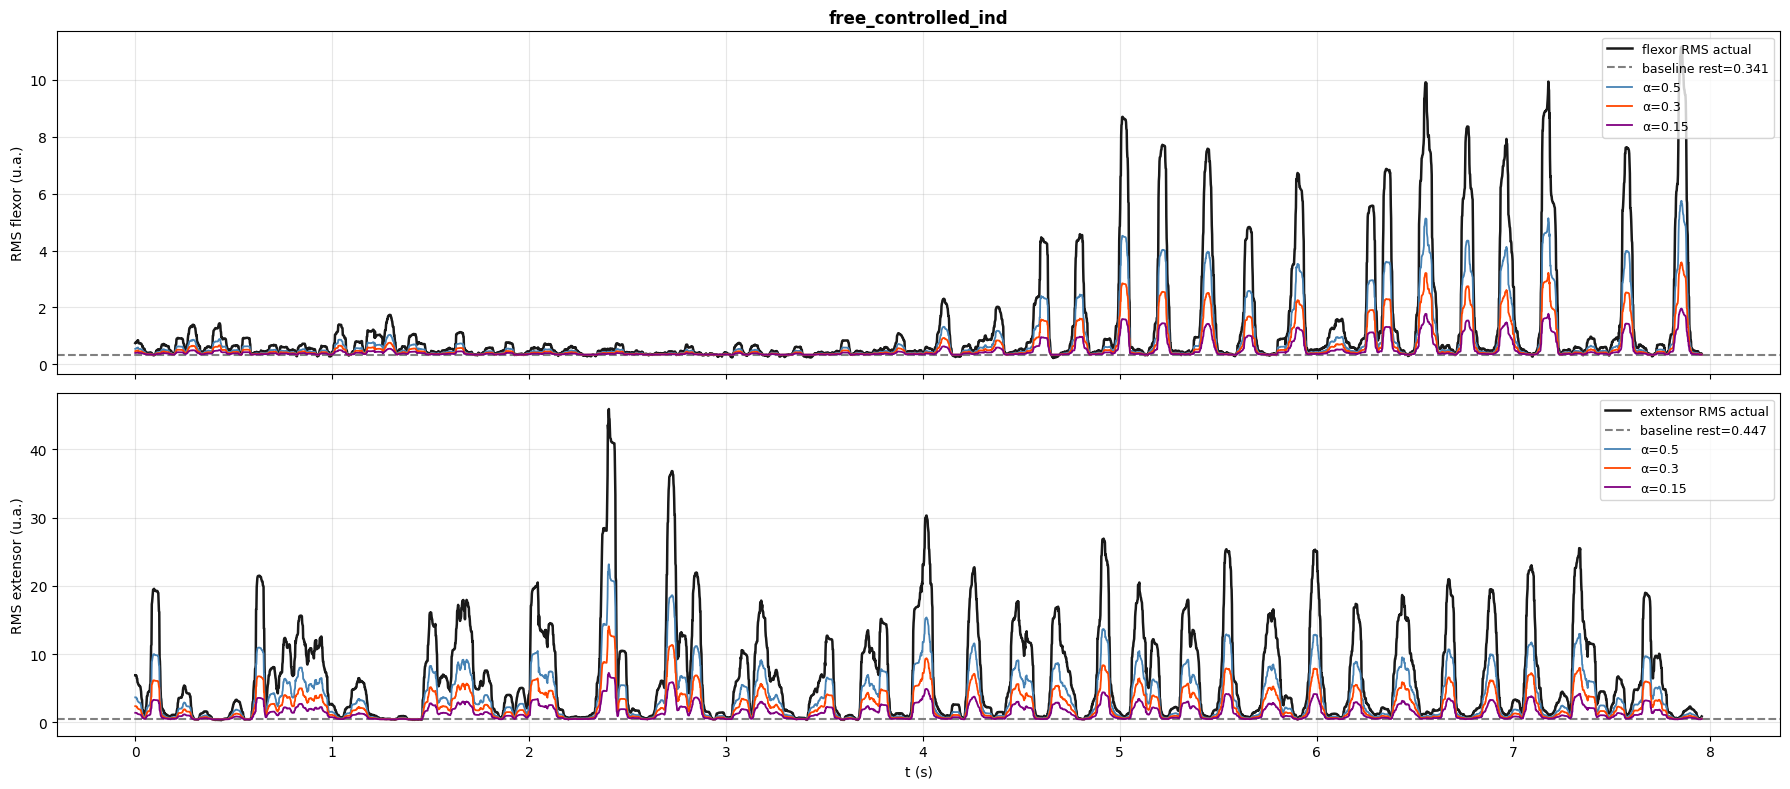

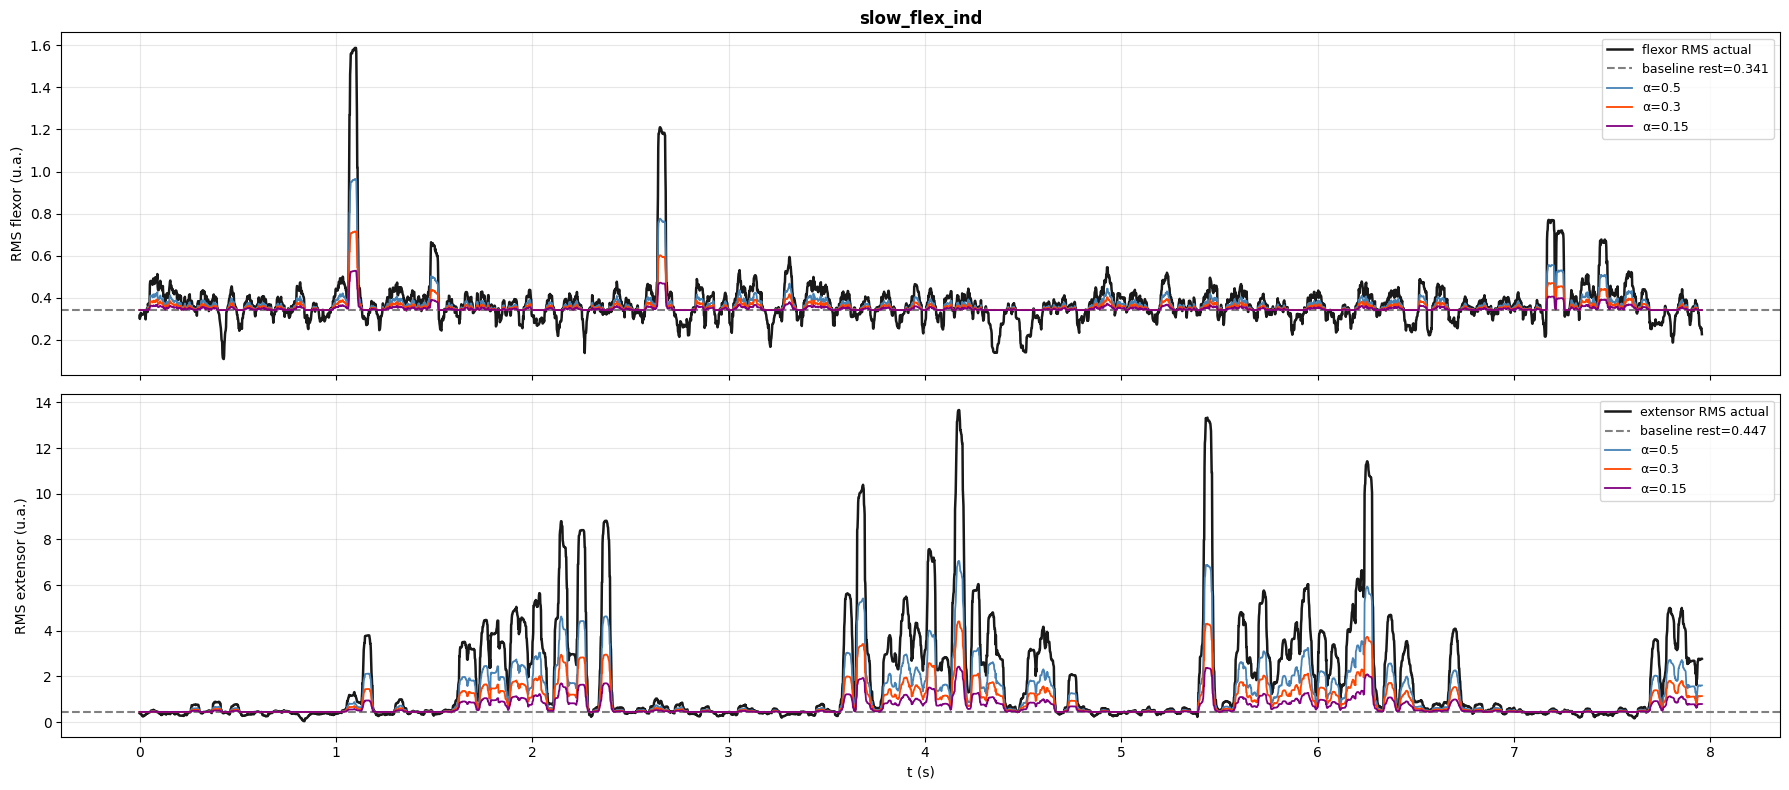

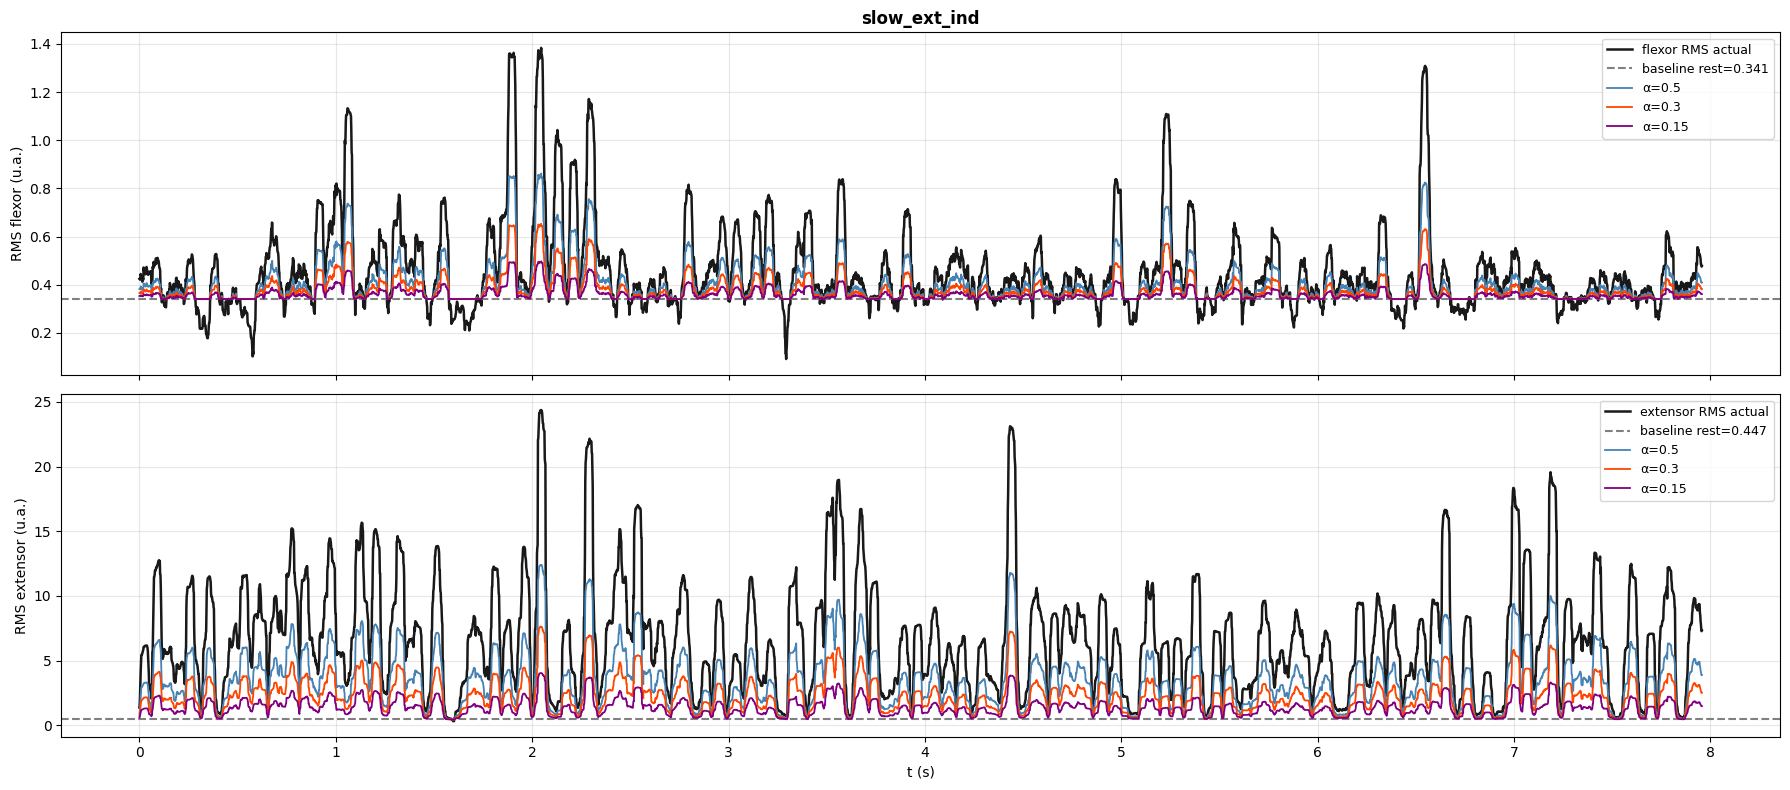

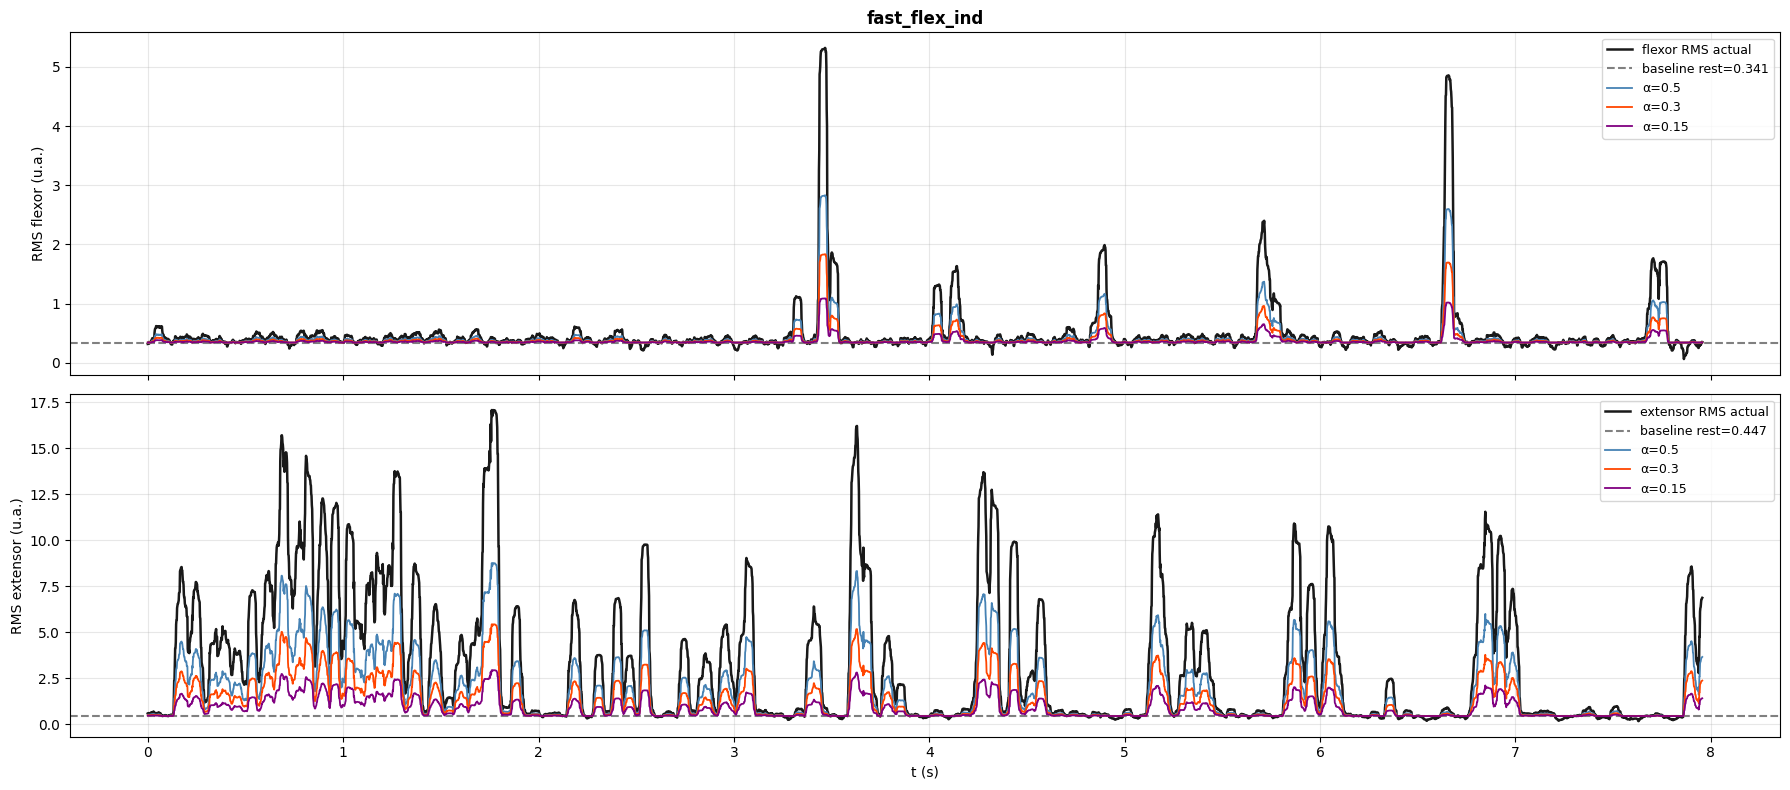

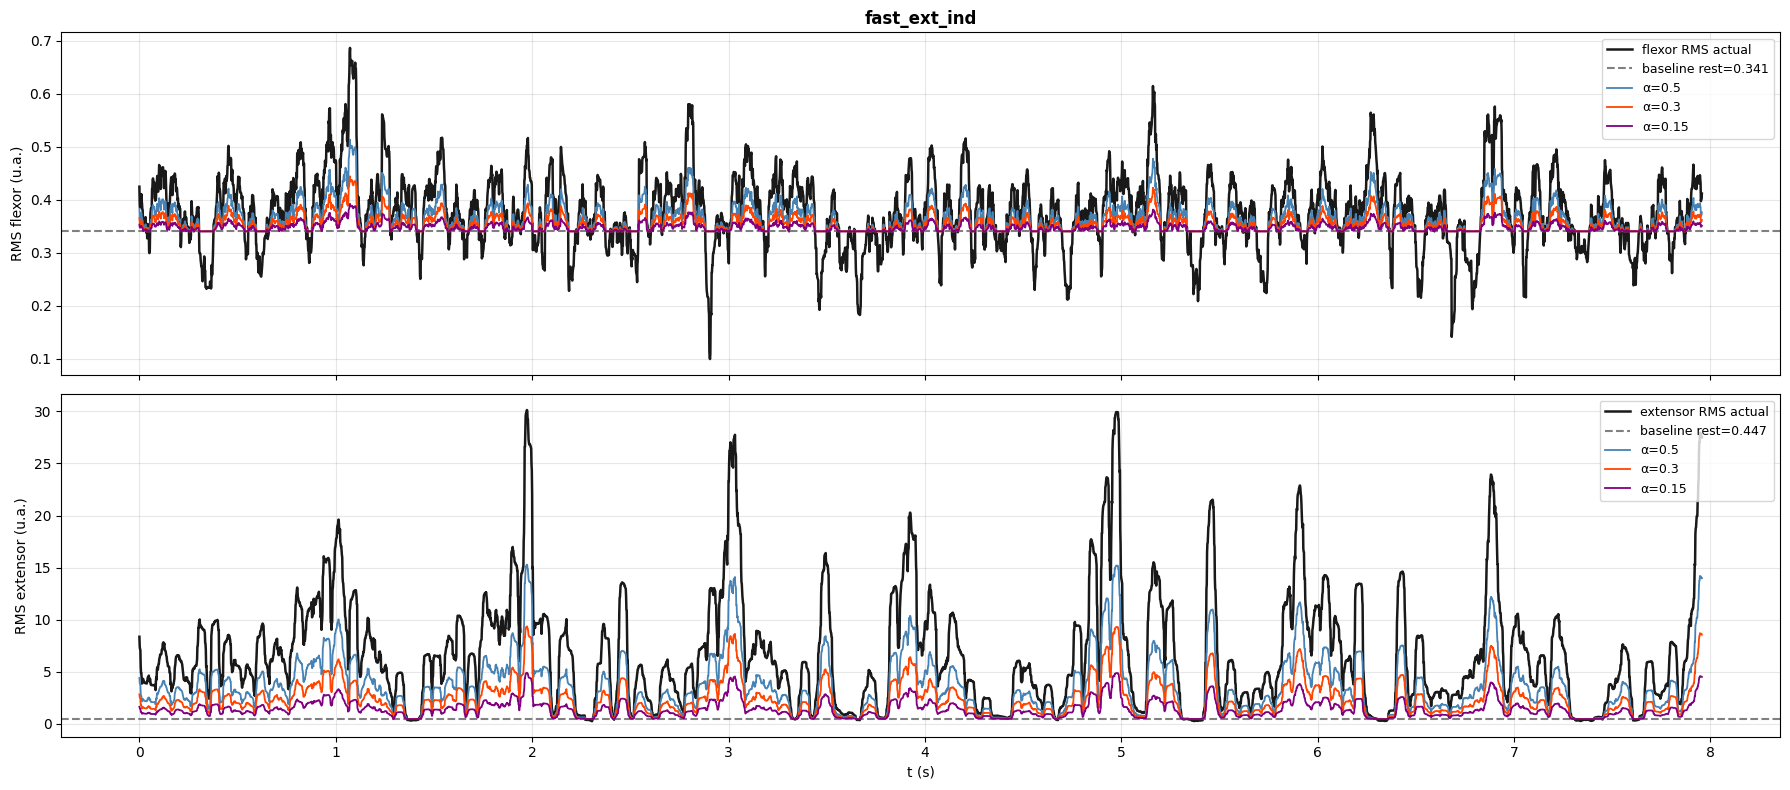

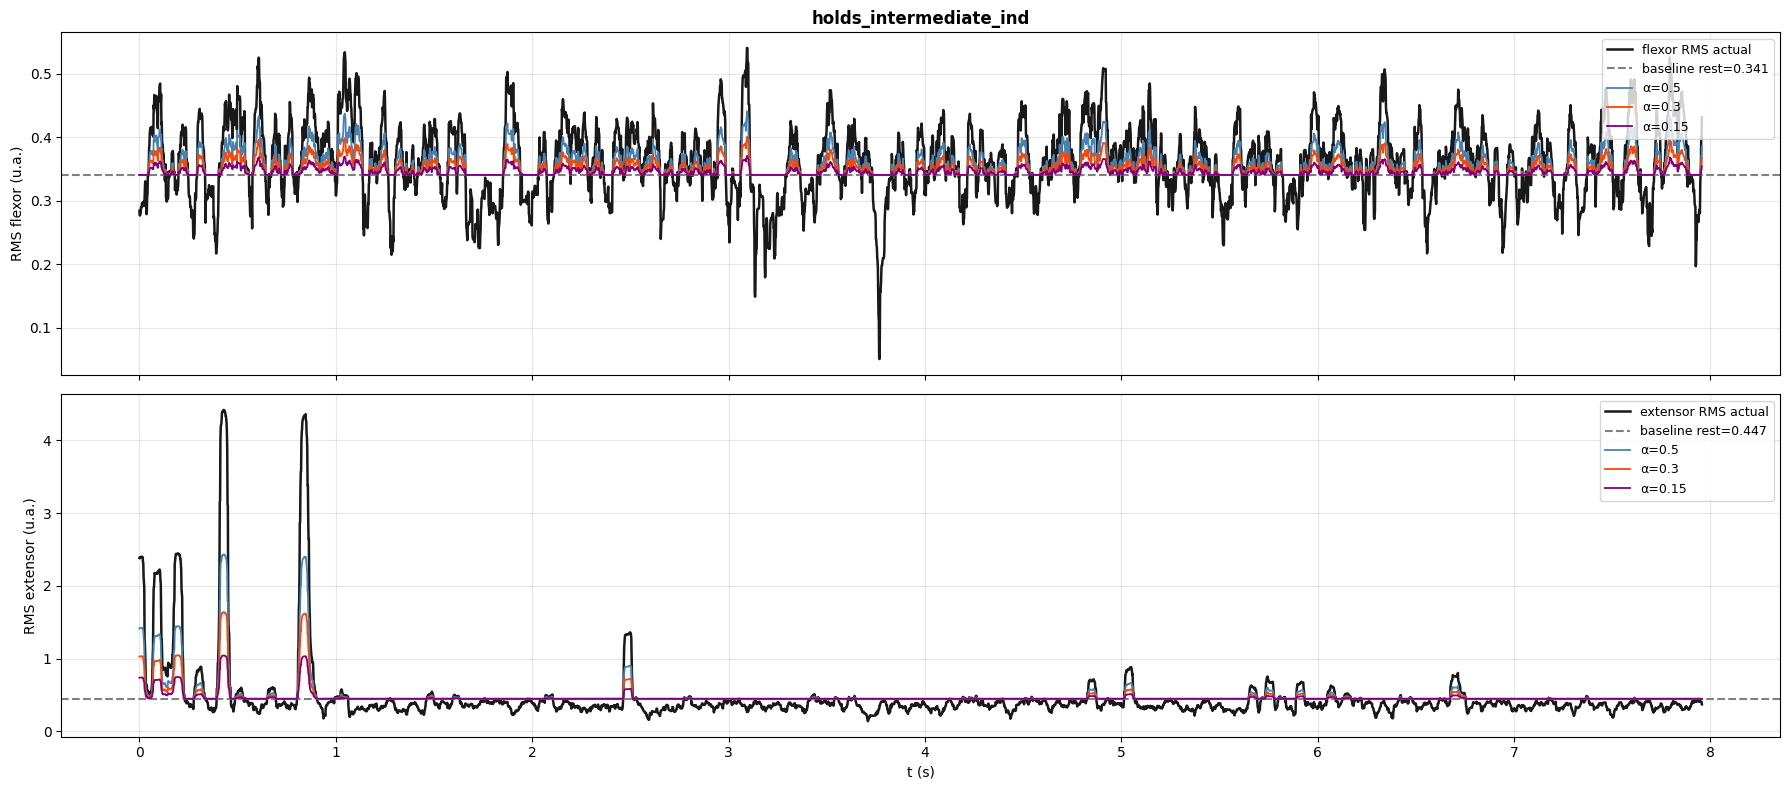

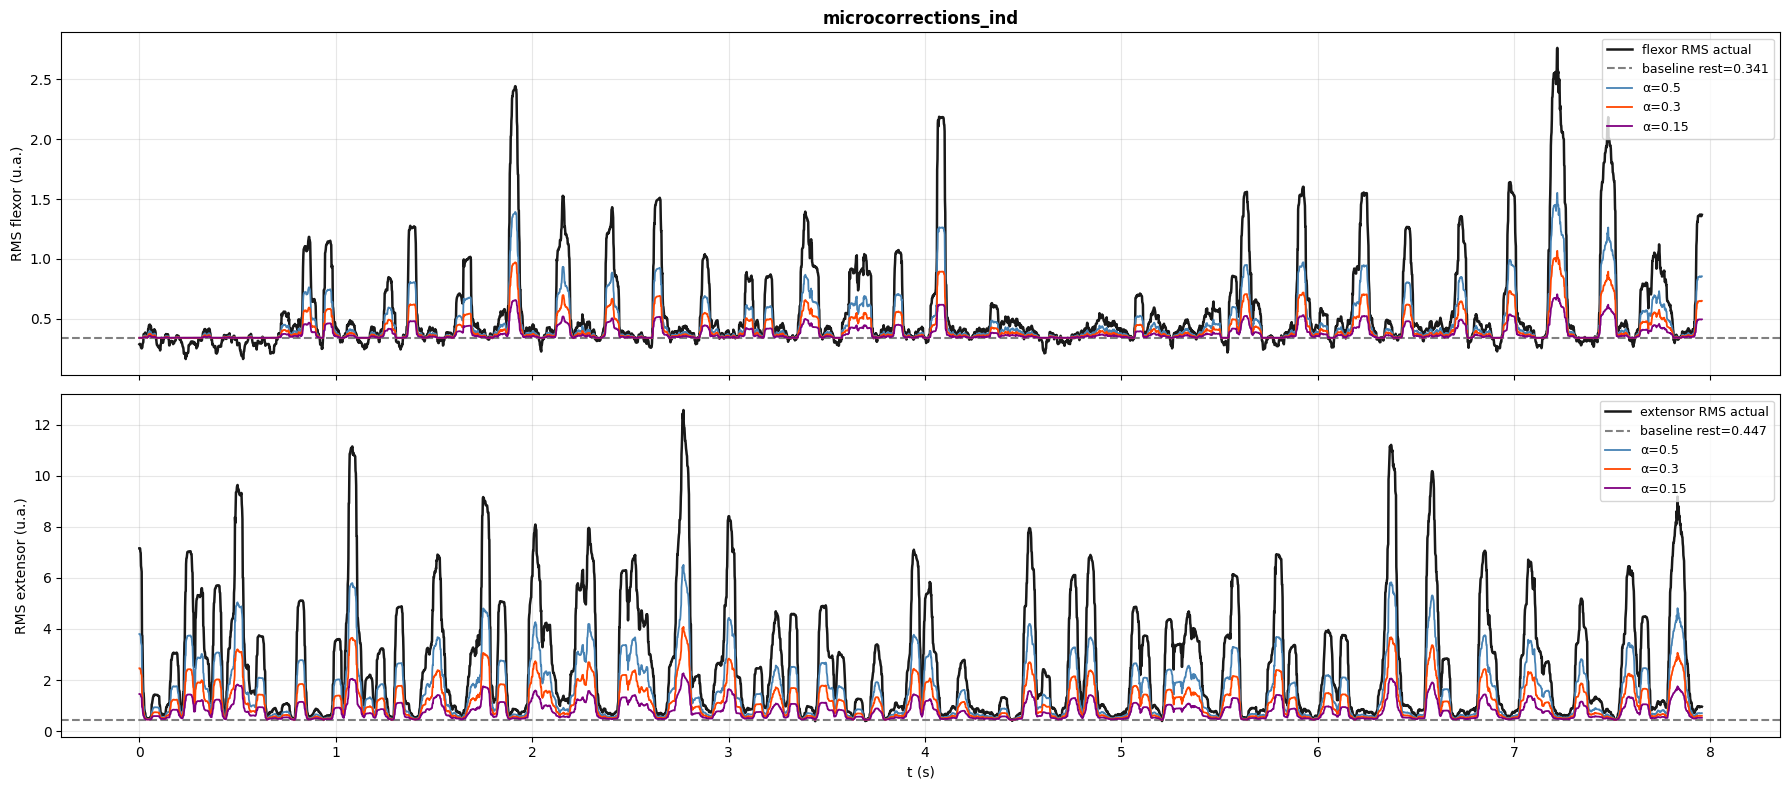

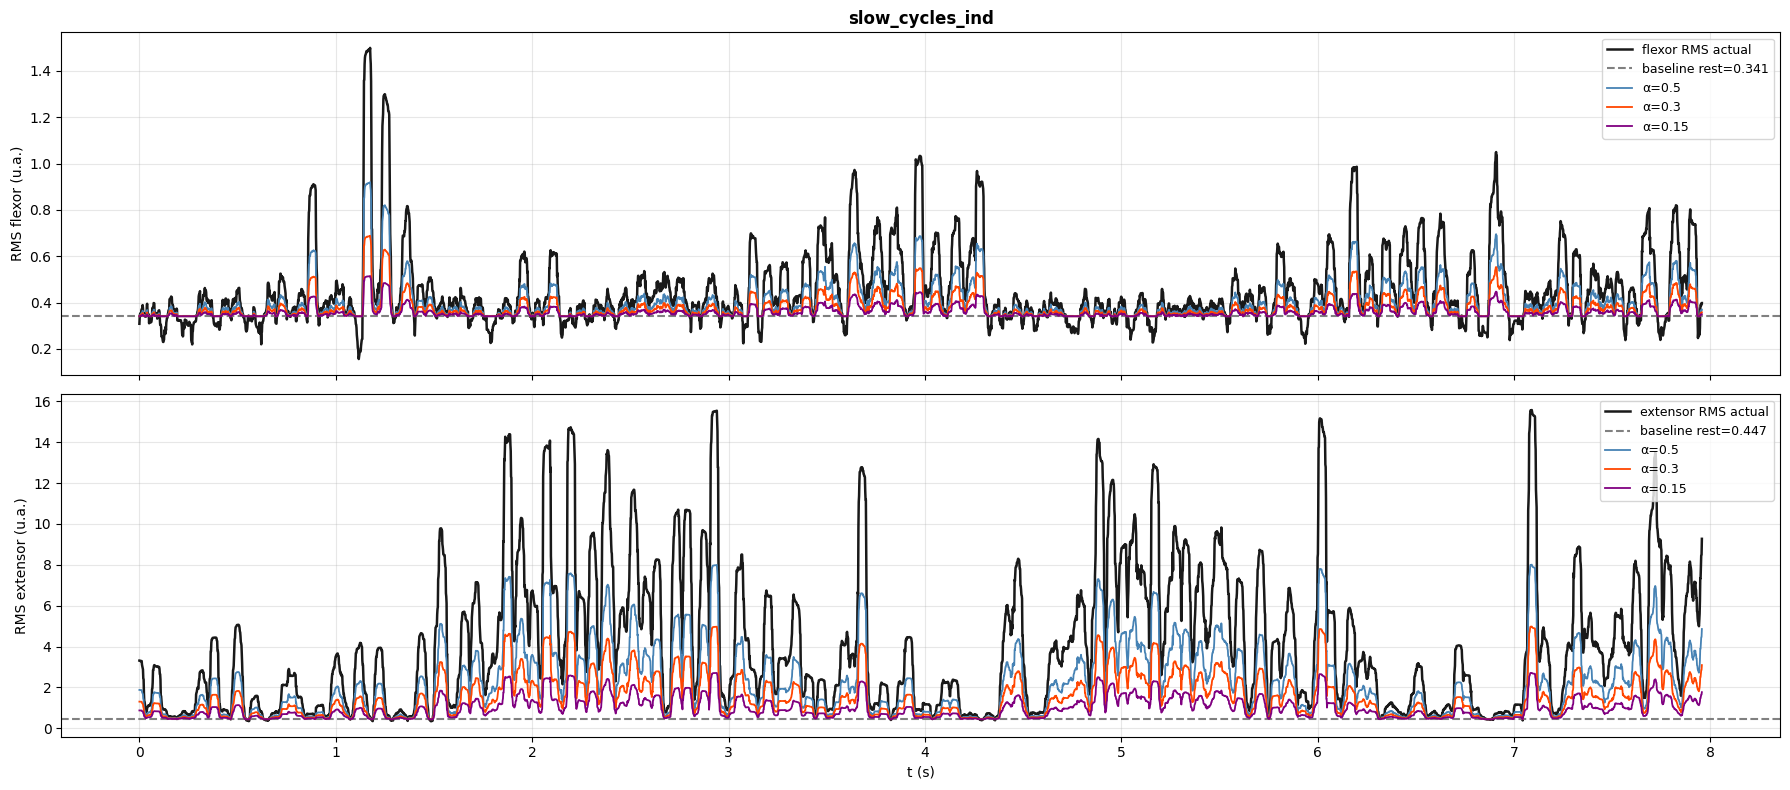

In [10]:
TASKS = [
    'free_controlled_ind', 'slow_flex_ind', 'slow_ext_ind',
    'fast_flex_ind', 'fast_ext_ind', 'holds_intermediate_ind',
    'microcorrections_ind', 'slow_cycles_ind',
]
PLOT_S = 8.0

for task in TASKS:
    idx = np.where(tasks == task)[0]
    if not len(idx): continue
    i0 = idx[0]; i1 = min(i0 + int(PLOT_S * fs), idx[-1] + 1)
    sl = slice(i0, i1); tr = t[sl] - t[i0]

    fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True)

    for ax, (rms, base, label) in zip(axes, [
        (rms_flx, base_flx, 'flexor'),
        (rms_ext, base_ext, 'extensor'),
    ]):
        ax.plot(tr, rms[sl], 'k', lw=1.8, label=f'{label} RMS actual', alpha=0.9)
        ax.axhline(base, color='gray', lw=1.5, ls='--', label=f'baseline rest={base:.3f}')
        for alpha, c in zip(ALPHAS, ACOLS):
            ax.plot(tr, compress(rms, base, alpha)[sl],
                    color=c, lw=1.3, label=f'α={alpha}')
        ax.set_ylabel(f'RMS {label} (u.a.)')
        ax.legend(fontsize=9, loc='upper right'); ax.grid(alpha=0.3)

    axes[0].set_title(f'{task}', fontweight='bold')
    axes[1].set_xlabel('t (s)')
    plt.tight_layout(); plt.show()


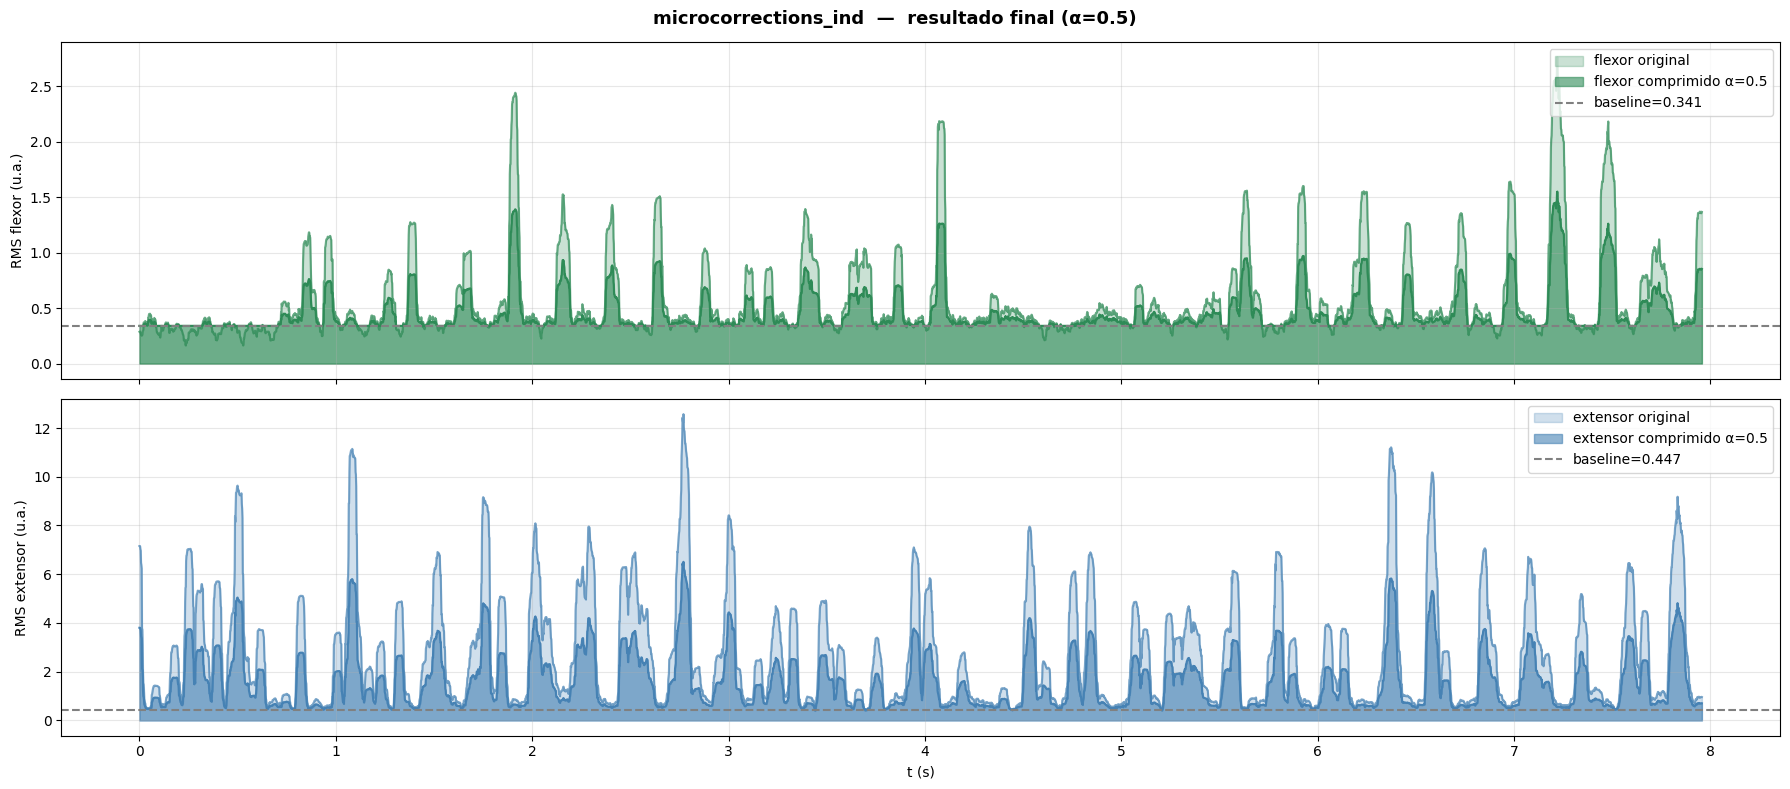


--- Amplitudes (p99) en microcorrections_ind ---
  flexor: original=2.1828  comprimido=1.2617  (58%)
  extensor: original=10.4151  comprimido=5.4313  (52%)


In [11]:
# Resultado final: microcorrections_ind, alpha=0.5
ALPHA_FINAL = 0.5
TASK_FINAL  = 'microcorrections_ind'

idx = np.where(tasks == TASK_FINAL)[0]
i0 = idx[0]; i1 = min(i0 + int(PLOT_S * fs), idx[-1] + 1)
sl = slice(i0, i1); tr = t[sl] - t[i0]

fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True)
fig.suptitle(f'{TASK_FINAL}  —  resultado final (α={ALPHA_FINAL})', fontsize=13, fontweight='bold')

for ax, (rms, base, label, color) in zip(axes, [
    (rms_flx, base_flx, 'flexor',   'seagreen'),
    (rms_ext, base_ext, 'extensor', 'steelblue'),
]):
    rms_c = compress(rms, base, ALPHA_FINAL)
    ax.fill_between(tr, 0, rms[sl],   color=color, alpha=0.25, label=f'{label} original')
    ax.fill_between(tr, 0, rms_c[sl], color=color, alpha=0.6,  label=f'{label} comprimido α={ALPHA_FINAL}')
    ax.plot(tr, rms[sl],  color=color, lw=1.5, alpha=0.7)
    ax.plot(tr, rms_c[sl], color=color, lw=1.5)
    ax.axhline(base, color='gray', lw=1.5, ls='--', label=f'baseline={base:.3f}')
    ax.set_ylabel(f'RMS {label} (u.a.)')
    ax.legend(fontsize=10, loc='upper right')
    ax.grid(alpha=0.3)

axes[1].set_xlabel('t (s)')
plt.tight_layout()
plt.show()

# Tabla de amplitudes
print(f'\n--- Amplitudes (p99) en {TASK_FINAL} ---')
for rms, base, label in [(rms_flx, base_flx, 'flexor'), (rms_ext, base_ext, 'extensor')]:
    rms_c = compress(rms, base, ALPHA_FINAL)
    p_orig = np.percentile(rms[sl], 99)
    p_comp = np.percentile(rms_c[sl], 99)
    print(f'  {label}: original={p_orig:.4f}  comprimido={p_comp:.4f}  ({p_comp/p_orig*100:.0f}%)')
